# データサイエンス実践A 第14講：実データを整える・回帰
### 新潟大学 創生学部（2026年度）
**講義日：2026年11月24日（火）**

1. 最初に、e-Stat などからダウンロードした**実データを Excel で整えて**読む（AM）。第３回課題で使うデータを探し始める。
1. 次に、散布図の点の並びに、**いちばん合う直線**（回帰直線）を引く（AO）。
1. 直線の**切片・傾き**と**決定係数**を読み取り、言葉で説明する。回帰の式を使って、**まだ無い値を予測**する。
1. 多項式回帰（曲線を当てはめる）は発展。できる人だけ。
1. セルは**上から順番に**実行すること（`Shift + Enter` で実行して次のセルへ進む）。

## 目次
**[前回の振り返り](#前回の振り返り)**

**[AM. 実データを整えて読む](#AM.-実データを整えて読む)**
- [AM-1 Excel で整える手順](#AM-1-Excel-で整える手順)
- [AM-2 整えたデータを読んで描く](#AM-2-整えたデータを読んで描く)

**[AO. 回帰（単回帰）](#AO.-回帰（単回帰）)**
- [AO-0 今日の完成形](#AO-0-今日の完成形)
- [AO-1 回帰とは](#AO-1-回帰とは)
- [AO-2 データを読んで散布図を描く](#AO-2-データを読んで散布図を描く)
- [AO-3 回帰直線を求める](#AO-3-回帰直線を求める)
- [AO-4 切片と傾きを読む](#AO-4-切片と傾きを読む)
- [AO-5 決定係数](#AO-5-決定係数)
- [AO-6 回帰直線を描く](#AO-6-回帰直線を描く)
- [AO-7 予測する](#AO-7-予測する)
- [AO-8 回帰の注意点](#AO-8-回帰の注意点)

**[AP. 発展（できる人だけ）](#AP.-発展（できる人だけ）)**
- [AP-1 多項式回帰（曲線を当てはめる）](#AP-1-多項式回帰（曲線を当てはめる）)

**[まとめ](#まとめ)**

---
# 前回の振り返り

- 前回は **if 文**（条件で分ける）、**for 文と if 文の組み合わせ**（条件で色分け）、**関数**（`def` → `return`）を学んだ
- 第５講では、Excel のファイルを `pd.read_excel('ファイル名', sheet_name='シート名')` で読んだ。今日は、ダウンロードした実データを読める形に整える
- 第４講の**散布図** `plt.scatter(x, y)` で、2つの量の関係を見た。今日はそこに直線を引く

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import japanize_matplotlib

from statsmodels.formula.api import ols

- 2行目の `from statsmodels.formula.api import ols` は、回帰の道具 `ols` を使えるようにする行
- `ModuleNotFoundError` が出たら、`statsmodels` が入っていない（Anaconda には最初から入っている）


---
# AM. 実データを整えて読む

## AM-1 Excel で整える手順

ダウンロードしたままの Excel は、そのままでは読めないことが多い。**Excel で整えてから** `read_excel` で読む。

1. e-Stat（政府統計の総合窓口）などから Excel（または csv）をダウンロードする
1. Excel で開き、**別名で保存**（元のファイルは残す）。csv は `.xlsx` で保存し直す（第５講 L-4）
1. 次のように整える
   - 表の上の説明の行、下の注釈の行を消す
   - **1行目を列名**にする（セルの結合は解除する）
   - **1列に1つの項目**、1行に1件のデータ
   - 数値の中の `-` や `…`、`,`、単位の文字（「人」「円」など）を消す
   - 列名は短く。空白や記号は入れない（例：`人口（千人）` → `人口`）。回帰で使える列名の条件は第15講でくわしく扱う
1. 整えたファイルを notebook と同じいつもの場所（ホームフォルダ）に置いて読む

| ダウンロードしたまま | 整えた後 |
|---|---|
| 1〜5行目にタイトルや説明 | 1行目が列名 |
| 「平成30年」と「2018」が混ざる | 年は数字だけ |
| `1,234`、`－`、`※1` | `1234`、空欄 |
| 「男」「女」が横に並んで2段の見出し | 1段の見出し（`男`、`女`） |

## AM-2 整えたデータを読んで描く

- 下は、気象庁のデータを整えた後の形の例。1行目が列名、1行に1か月分

In [2]:
df_rain = pd.read_excel('dsa2026data.xlsx', sheet_name='降水量')
df_rain

,月,降水量,気温
0,1,180.0,4.3
1,2,114.5,4.8
2,3,168.0,6.0
3,4,54.0,13.7
4,5,128.0,17.1
5,6,57.0,22.2
6,7,376.5,26.2
7,8,42.0,28.0
8,9,292.0,25.0
9,10,144.5,18.7


- 読めたら、まず `df.head()` や `df` で中身を見て、**列名**と**数値が数値として読めているか**を確かめる
- `df.dtypes` で列の型を見る。数値の列が `object`（文字）になっていたら、Excel に `-` や `,` が残っている

月        int64
降水量    float64
気温     float64
dtype: object


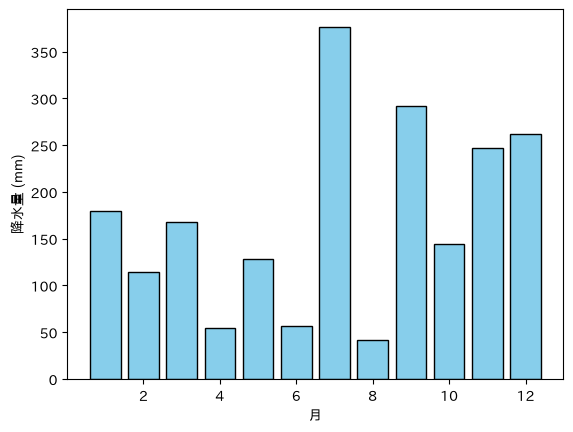

In [3]:
print(df_rain.dtypes)

plt.bar(df_rain['月'], df_rain['降水量'], color='skyblue', edgecolor='k')
plt.xlabel('月')
plt.ylabel('降水量 (mm)')
plt.show()

### 使ってみよう
- e-Stat で、興味のあるデータ（2つの量の関係が見られるもの）を探してダウンロードし、AM-1 の手順で整えてみよう
- 第３回課題（第15講で出題）で使う。「人口と○○」「年と○○」のように、**2つの列**があるものを選ぶ

In [4]:
# 整えたファイルを読んでみよう
# df = pd.read_excel('ファイル名.xlsx', sheet_name='シート名')
# df.head()

---
# AO. 回帰（単回帰）

## AO-0 今日の完成形

レストランの食事代とチップの散布図に、**回帰直線**（赤）を引いたもの。直線の式と決定係数をタイトルに入れている。

1. **全部コピーして**自分の notebook のセルに貼り付け、実行する
1. まずは**列名を変えて**、グラフのどこが変わるかを確かめる
1. そのあと部品（[1]〜[4]）の働きを1つずつ学ぶ（AO-1〜AO-6）

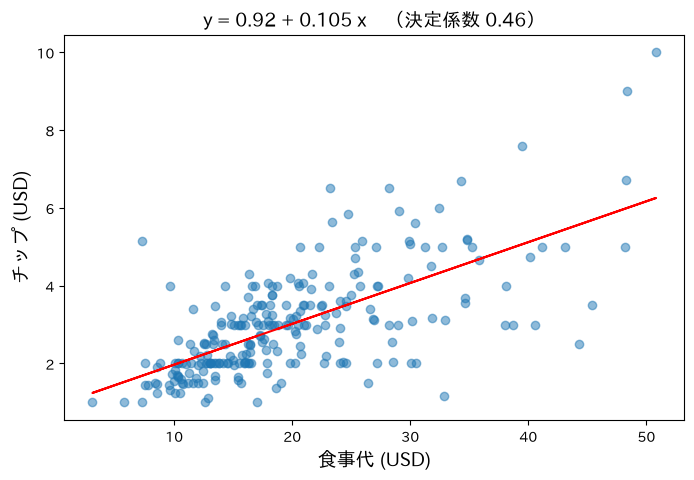

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import japanize_matplotlib
from statsmodels.formula.api import ols

df_tip = pd.read_excel('dsa2026data.xlsx', sheet_name='tip_data')

res = ols('tip ~ total_bill', data=df_tip).fit()  # [1] 回帰直線を求める
a = res.params['Intercept']  # [2] 切片
b = res.params['total_bill']  # [2] 傾き
r2 = res.rsquared  # [3] 決定係数

plt.figure(figsize=(8, 5))
plt.scatter(df_tip['total_bill'], df_tip['tip'], alpha=0.5, zorder=2)
plt.plot(df_tip['total_bill'], res.predict(), color='r', zorder=3)  # [4] 回帰直線
plt.title(f'y = {a:.2f} + {b:.3f} x　（決定係数 {r2:.2f}）', fontsize=14)
plt.xlabel('食事代 (USD)', fontsize=14)
plt.ylabel('チップ (USD)', fontsize=14)
plt.show()

### 変えてみよう（1か所変えたら、もう一度実行する）

- タイトルの `f'…{a:.2f}…'`（f 文字列）は、変数の値を文字の中に入れる書き方。第15講で学ぶので、今は写して使えばよい

- `'tip ~ total_bill'` → `'tip ~ size'`（人数とチップ）。`b = res.params['total_bill']` も `'size'` に、`plt.scatter`・`plt.xlabel` も変える
- `color='r'` → `color='orange'`、`alpha=0.5` → `alpha=0.2`

| 番号 | 部品 | 書き方 | 学ぶところ |
|---|---|---|---|
| [1] | 回帰直線を求める | `res = ols('y の列名 ~ x の列名', data=df).fit()` | AO-3 |
| [2] | 切片・傾き | `res.params` | AO-4 |
| [3] | 決定係数 | `res.rsquared` | AO-5 |
| [4] | 回帰直線を描く | `plt.plot(x, res.predict())` | AO-6 |

In [6]:
# 上のコードを貼り付けて、値を変えてみよう

## AO-1 回帰とは

- 散布図の点の並びに、**いちばん合う直線**を引くこと。直線の式は **y = 切片 + 傾き × x**
  - **切片**：x が 0 のときの y
  - **傾き**：x が 1 増えると、y がどれだけ増えるか
- 「いちばん合う」＝ 点と直線の**縦方向のずれ（の2乗）の合計が最小**になる直線（最小二乗法。`ols` は Ordinary Least Squares の略）
- x が1つのときを**単回帰**、2つ以上のときを**重回帰**（第15講の発展）という

## AO-2 データを読んで散布図を描く

- `tip_data` は、アメリカのレストランの244件の会計のデータ
- 列：`total_bill`（食事代）、`tip`（チップ）、`sex`、`smoker`、`day`（曜日）、`time`（昼・夜）、`size`（人数）

In [7]:
df_tip = pd.read_excel('dsa2026data.xlsx', sheet_name='tip_data')
df_tip.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


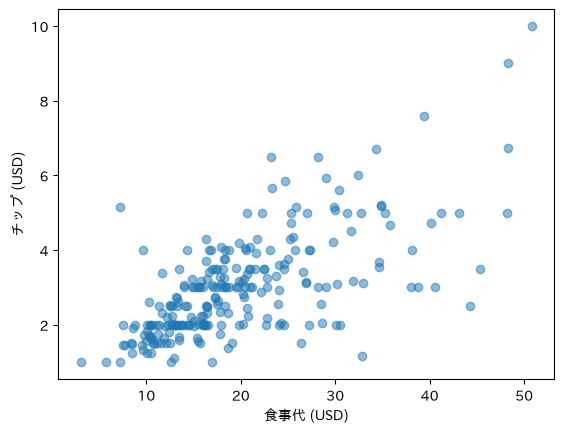

In [8]:
plt.scatter(df_tip['total_bill'], df_tip['tip'], alpha=0.5)
plt.xlabel('食事代 (USD)')
plt.ylabel('チップ (USD)')
plt.show()

- 右上がり：食事代が高いほど、チップも多い傾向がある。この傾向を直線で表す

## AO-3 回帰直線を求める

- `ols('y の列名 ~ x の列名', data=データフレーム).fit()` と書く
  - `~` の**左が y**（予測したいもの）、**右が x**（手がかり）。`'tip ~ total_bill'` は「チップを食事代で説明する」
  - `.fit()` で計算する。結果を `res` に入れておく
- 列名に空白や記号があると使えない。Excel の段階で短い列名にしておく（AM-1。くわしい条件は第15講）

In [9]:
res = ols('tip ~ total_bill', data=df_tip).fit()
print(res.params)

Intercept     0.920270
total_bill    0.105025
dtype: float64


## AO-4 切片と傾きを読む

- `res.params` の `Intercept` が**切片**、`total_bill` が**傾き**
- この例では y = 0.92 + 0.105 × x
  - 傾き 0.105：「食事代が1ドル増えると、チップは約0.1ドル増える」＝ チップはだいたい食事代の1割
  - 切片 0.92：「食事代0ドルなら、チップ0.92ドル」。実際には食事代0の会計は無いので、**切片はあまり意味を持たないことが多い**
- 1つずつ取り出すときは `res.params['Intercept']`、`res.params['total_bill']`

In [10]:
a = res.params['Intercept']
b = res.params['total_bill']
print('切片', a)
print('傾き', b)

切片 0.9202696135546727
傾き 0.10502451738435337


## AO-5 決定係数

- **決定係数**（R²、0〜1）：直線がどれくらい点に合っているか。1 に近いほどよく合う
- 目安：0.5 以上ならまあまあ合っている、0.2 より小さければ直線ではほとんど説明できていない（分野によって目安は違う）

In [11]:
print('決定係数', res.rsquared)

決定係数 0.45661658635167646


- 0.46 くらい：チップの多さの半分くらいは食事代で説明できる。残りは人数・曜日・人の気前など、ほかの理由

## AO-6 回帰直線を描く

- `res.predict()` で、データの x それぞれに対する**直線上の y** が求まる。これを `plt.plot` で結ぶと回帰直線になる
- `zorder=` は重なりの順番。大きいほど手前に描かれる（直線を点の手前に）

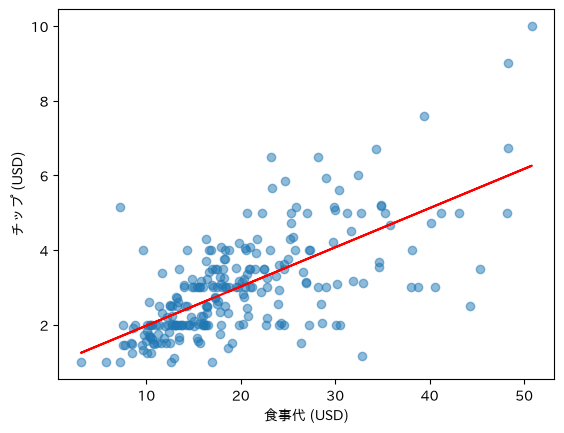

In [12]:
plt.scatter(df_tip['total_bill'], df_tip['tip'], alpha=0.5, zorder=2)
plt.plot(df_tip['total_bill'], res.predict(), color='r', zorder=3)
plt.xlabel('食事代 (USD)')
plt.ylabel('チップ (USD)')
plt.show()

## AO-7 予測する

- 式に x を入れれば、y を予測できる。食事代が 30 ドルなら、チップは 0.92 + 0.105 × 30 ≒ 4.07 ドル
- （補足）`res.predict(pd.DataFrame({'total_bill': [30, 50]}))` と書くと、いくつかの x についてまとめて予測できる

In [13]:
print(a + b * 30)
# 補足：まとめて予測する
print(res.predict(pd.DataFrame({'total_bill': [30, 50]})))

4.071005135085274
0    4.071005
1    6.171495
dtype: float64


- データの範囲（ここでは 3〜51 ドルくらい）の**外側の予測**は当たらないことが多い。「食事代1000ドルならチップ106ドル」とは言えない

### 使ってみよう
- `accident` シートで、`交通事故件数`（x）と `負傷者数`（y）の回帰直線を求め、散布図に描いてみよう
- 傾きを言葉で説明してみよう（「事故が1件増えると、負傷者は○人増える」）

In [14]:
df_acc = pd.read_excel('dsa2026data.xlsx', sheet_name='accident')

# ここで試してみよう

## AO-8 回帰の注意点

| 注意 | 説明 |
|---|---|
| まず散布図を見る | 点が曲線状に並んでいたら、直線は合わない（AP-1） |
| 関係があっても原因とは限らない | アイスの売上と水難事故は、どちらも「暑さ」で増える。回帰は「一緒に動く」ことしか言えない |
| 外れ値に引っぱられる | 極端な点が1つあると、直線が大きく傾く |
| 範囲の外は予測しない | AO-7 |

---
# AP. 発展（できる人だけ）

## AP-1 多項式回帰（曲線を当てはめる）

- `I(x ** 2)` を足すと2次式（放物線）：y = 切片 + 係数1 × x + 係数2 × x²
- 一人あたりGDPと平均寿命：GDP が低いうちは急に伸び、高くなると伸びが鈍る → 直線より曲線が合う

直線の決定係数 0.4761052267692292
2次式の決定係数 0.7185594845335047


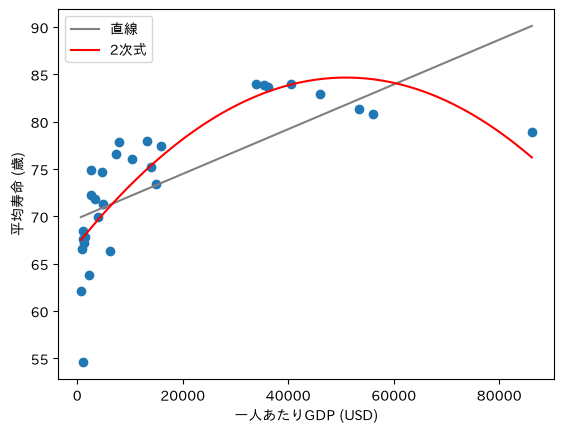

In [15]:
df_wb = pd.read_excel('dsa2026data.xlsx', sheet_name='worldbank')

res1 = ols('出生時平均寿命 ~ 一人あたりGDP', data=df_wb).fit()
res2 = ols('出生時平均寿命 ~ 一人あたりGDP + I(一人あたりGDP ** 2)', data=df_wb).fit()
print('直線の決定係数', res1.rsquared)
print('2次式の決定係数', res2.rsquared)

x = np.linspace(df_wb['一人あたりGDP'].min(), df_wb['一人あたりGDP'].max(), 100)
plt.scatter(df_wb['一人あたりGDP'], df_wb['出生時平均寿命'])
plt.plot(x, res1.predict(pd.DataFrame({'一人あたりGDP': x})), color='gray', label='直線')
plt.plot(x, res2.predict(pd.DataFrame({'一人あたりGDP': x})), color='r', label='2次式')
plt.xlabel('一人あたりGDP (USD)')
plt.ylabel('平均寿命 (歳)')
plt.legend()
plt.show()

- 列名が日本語でも、空白や記号がなければ `ols` の式にそのまま書ける（第15講）
- `np.linspace(最小, 最大, 100)` は、最小から最大までを100等分した数（なめらかな曲線を描くため）
- 次数を上げすぎると、点にぴったり合っても予測には役に立たない曲線になる（過学習）

---
# まとめ

| やりたいこと | 書き方 |
|---|---|
| 実データを読む | Excel で整えてから `pd.read_excel(…)`、`df.dtypes` で型を確かめる |
| 準備 | `from statsmodels.formula.api import ols` |
| 回帰直線を求める | `res = ols('y の列名 ~ x の列名', data=df).fit()` |
| 切片・傾き | `res.params`（`res.params['Intercept']`、`res.params['x の列名']`） |
| 決定係数 | `res.rsquared` |
| 回帰直線を描く | `plt.plot(df['x の列名'], res.predict(), color='r')` |
| 予測 | `a + b * x の値`（補足：`res.predict(pd.DataFrame({'x の列名': [値]}))`） |

- 傾きは「x が 1 増えると y がどれだけ増えるか」。決定係数は直線の合い具合（0〜1）
- 回帰は「一緒に動く」ことしか言えない。原因かどうかは別に考える

次回（第15講）は**時系列**と **f 文字列**、`ols` で使える**列名の条件**、そして**自分で選んだデータでグラフ＋回帰**（第３回課題）。